## **Do cuisines that are more complex to cook offer better nutritional value, and are they rewarded with higher popularity?**

Group members: 
1. On Wan Yu A0301006E
2. Tan Guan Ming Terence A0308316J
3. Jessie Wong Lei A0299724L
4. Yee Jen Mok Lionel A0307914A
5. Ho Shao En A0307554A
6. Koh Ying Rou A0301369H

Topic of Choice: All Recipes

Purpose: We study how cusines complexity affects nutrition value and whether more nutritious recicpes are more popular. We build an analysis-ready data by cleaning `cuisines` dataset, followed by feature engineering some features and finally exploring trends. 

In [1]:
import os
from datetime import datetime as dt
import math
import numpy as np
import pandas as pd
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from matplotlib.patches import Patch, Rectangle
import requests, certifi, io, pandas as pd
import matplotlib.patheffects as pe
os.environ["SSL_CERT_FILE"] = certifi.where()


### **Introduction**

This project explores whether **cuisines that are more complex to cook offer better nutritional value, and if they rewarded with higher popularity**. The dataset originate from the [TidyTuesday project (16 September 2025)](https://github.com/rfordatascience/tidytuesday/blob/main/data/2025/2025-09-16/readme.md), which adapts data from the tastyR package (a dataset assembled from [Allrecipes.com](https://cran.r-project.org/web/packages/tastyR/index.html)) and was prepared for analysis in R. 

A collection of recipe datasets scraped from https://www.allrecipes.com/, containing two complementary datasets: `allrecipes` with 14,426 general recipes, and `cuisines` with 2,218 recipes categorized by country of origin. Both datasets include comprehensive recipe information such as ingredients, nutritional facts (calories, fat, carbs, protein), cooking times (preparation and cooking), ratings, and review metadata. 

For this analysis, we will be only using `cuisines` dataset. 


load raw data. Pull `cuisines` CSVs from TidyTuesday GitHUb

In [2]:
url2 = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-16/cuisines.csv' #cuisines 
r2 = requests.get(url2, verify=certifi.where())
r2.raise_for_status()
cuisines = pd.read_csv(io.StringIO(r2.text))

### **Dataset Used**
we used `cuisines` dateset from the TidyTuesday (2025-09-16) release: 
- **cuisines**: name, country, url, author, date_published, ingredients, calories, fat, carbs, protein, avg_rating, total_ratings (truncated to the thousands, unless there were less than 1000 ratings total), reviews (truncated to the thousands, unless there were less than 1000 ratings total), prep_time (min), cook_time (min), total_time (min), servings 


### **Data Cleaning**
check `cuisines` for missing values and duplicates. For missing nutritional values (calories, fat, carbs, protein) and missing cooking duration (prep_time,cook_time, total_time),  we will drop these rows. 
For engagement-related variables such as **reviews** and **total_ratings**, missing values were replaced with zero, as these likely indicate that a recipe has not received any user interaction. In contrast, missing values in **avg_rating** were preserved as NA, since a lack of ratings does not imply poor quality and assigning a value of zero would introduce bias. 

In [3]:
cuisines.isna().sum()

name                0
country             0
url                 0
author              0
date_published      0
ingredients         1
calories           32
fat                55
carbs              35
protein            39
avg_rating         97
total_ratings      97
reviews           108
prep_time           0
cook_time           0
total_time          0
servings            2
dtype: int64

In [4]:
cuisines_na = cuisines.dropna(subset=["calories", "fat", "carbs", "protein", "prep_time", "cook_time", "total_time"])
cuisines_clean = cuisines_na.copy()
cuisines_clean[["total_ratings", "reviews"]] = (
    cuisines_clean[["total_ratings", "reviews"]].fillna(0)
)

cuisines_clean.isna().sum()

name               0
country            0
url                0
author             0
date_published     0
ingredients        0
calories           0
fat                0
carbs              0
protein            0
avg_rating        92
total_ratings      0
reviews            0
prep_time          0
cook_time          0
total_time         0
servings           1
dtype: int64

In [5]:
cuisines_clean.duplicated(["name", "url"]).sum()

np.int64(0)

We filter out recipes that have **total time** of less than 0 min and more than 1 day.  

In [6]:
cuisines_clean = cuisines_clean[
    (cuisines_clean['total_time'] > 0) &
    (cuisines_clean['total_time'] <= 1440)
].copy()

We keep only cuisines with more than 50 recipes so that group comparisons will be more statistically meaningful. 

In [7]:
cuisine_counts = cuisines_clean.groupby('country').size()
reliable_cuisines = cuisine_counts[cuisine_counts >= 50].index
cuisines_final = cuisines_clean[cuisines_clean['country'].isin(reliable_cuisines)].copy()

### **Final cleaned dataset**
After cleaning, the dataset retains 1423 recipes from 24 unique countries, with only **avg_rating** columns that consist of NA values since they represent no ratings yet. 

In [8]:
print("Shape:", cuisines_final.shape)
print("\nSample:")
print(cuisines_final.head(8))
print("Countries:", cuisines_final['country'].nunique())
print(cuisines_final["country"].unique())
print("Number of recipes with no ratings:", cuisines_final["avg_rating"].isna().sum())

Shape: (1423, 17)

Sample:
                                              name  \
0                  Saganaki (Flaming Greek Cheese)   
1                             Coney Island Knishes   
2                     Diana's Hawaiian Bread Rolls   
4                               Tex-Mex Sheet Cake   
5                       Newfoundland Jigg's Dinner   
6   Pasta e Ceci (Italian Chickpea and Pasta Stew)   
9            Pan con Tomate (Spanish Tomato Bread)   
10                         Traci's Adobo Seasoning   

                         country  \
0                          Greek   
1                         Jewish   
2   Australian and New Zealander   
4                        Tex-Mex   
5                       Canadian   
6                        Italian   
9                        Spanish   
10                      Filipino   

                                                  url           author  \
0   https://www.allrecipes.com/recipe/263750/flami...   John Mitzewich   
1   https://w

### **Interesting findings from Data Analysis**

#### **Review counts are highly right-skewed**
While the typical recipe attracts just 24 reviews, the mean is pulled up to 87 by a small number of popular recipes, with top 10% of recipes exceeding 254 reviews and the most-reviewed recipe reaching 975. Over a third of recipes (34.5%) have fewer than 10 reviews, suggesting most recipes have a limited audience while a handful dominate engagement. 

In [9]:
print("Median reviews:", round(cuisines_final["reviews"].median(), 0))
print("Mean reviews:", round(cuisines_final["reviews"].mean(), 0))
print("90th percentile:", round(cuisines_final["reviews"].quantile(0.90), 0))
print("Max reviews:", cuisines_final["reviews"].max())
print("% with < 10 reviews:", round((cuisines_final["reviews"] < 10).mean() * 100, 1))

Median reviews: 24.0
Mean reviews: 87.0
90th percentile: 254.0
Max reviews: 975.0
% with < 10 reviews: 34.5


#### **Wide spread in cooking total time**
The typical recipe takes around 60 minutes in total, with a median prep time of just 15 minutes and cook time of 25 minutes. However, the range is extreme as the longest recipe clocks in at 1,135 minutes which is nearly 19 hours. this points to a long tail of highly involved dishes that sit far outside the everyday cooking experience.

In [10]:
print("\n--- Time / Complexity ---")
print("Median prep time:", round(cuisines_final["prep_time"].median(), 1), "mins")
print("Median cook time:", round(cuisines_final["cook_time"].median(), 1), "mins")
print("Median total time:", round(cuisines_final["total_time"].median(), 1), "mins")
print("Max total time:", round(cuisines_final["total_time"].max(), 1), "mins")


--- Time / Complexity ---
Median prep time: 15.0 mins
Median cook time: 25.0 mins
Median total time: 60.0 mins
Max total time: 1135 mins


In [11]:
corr_vars = [
    "avg_rating", "reviews",
    "prep_time", "cook_time", "total_time",
    "calories", "fat", "carbs", "protein"
]
corr = cuisines_final[corr_vars].corr(numeric_only=True)


#### **Calories track fat content closely**
Unsurprisingly, calories and fat content are strongly correlated (r = 0.87), reflecting the calorie density of fat. While this relationship is largely expected, it confirms the data is internally consistent and that fat is the dominant macronutrient driver of a recipe's caloric load.

In [12]:
print("calories vs fat:", round(corr.loc["calories", "fat"], 3))

calories vs fat: 0.866


#### **Cook time vs Prep time**
Total cooking time is more strongly associated with cook time (r = 0.55) than prep time (r = 0.22), suggesting that most time in the kitchen is passive rather than active. Thus, total time alone is a poor proxy for complexity because it's largely driven by passive cook time, not actual cooking effort
This motivated our definition of coooking complexity as prep time as a proportion of total time which captures hands-on effort rather than waiting.

In [13]:
print("total_time vs cook_time:", round(corr.loc["total_time", "cook_time"], 3))
print("total_time vs prep_time:", round(corr.loc["total_time", "prep_time"], 3))

total_time vs cook_time: 0.545
total_time vs prep_time: 0.223


### **Q1. What makes a cuisine complex?**

There are many ways to determine the complexity of a recipe, the number of ingredients, the amount of preparation required, the flavour profiles etc.

Thus, it is of utmost importance for us to set our definition of complexity clearly.



####  **Recipe Time & Complexity**
Every recipe consists of two main time components, cook time and prep time.

| Time Type | Definition |
|--------------|----------------|
| Prep Time | Time involving **active labour** — ingredient preparation, chopping, measuring, organising, etc. |
| Cook Time | Time food spends **under heat** (baking, boiling, frying, simmering, etc.). |


#### **Complexity Rating**
A recipe’s **complexity rating** is determined by the ratio of prep time to the total time: **Prep Time ÷ Total Time**

- **Higher prep percentage** → More intensive: Requires constant attention and stronger time management.

- **Higher cook percentage** → Less intensive: Allows for more passive waiting.


| **Recipe** | **Prep Time** | **Cook Time** | **Total Time** | **Prep %** | **Complexity** |
|-----------|--------------|---------------|---------------|-----------|---------------|
| Recipe A | 60 min | 120 min | 180 min | **33%** | Less complex |
| Recipe B | 60 min | 10 min | 70 min | **87%** | More complex |



In [14]:
qn1 = cuisines_final.groupby(by = "country").agg({"prep_time": "mean", "cook_time": "mean"}).reset_index()
qn1["total_time"] = qn1["prep_time"] + qn1["cook_time"]
qn1["prep_pct"] = qn1["prep_time"] / qn1["total_time"] * 100
qn1 = qn1.sort_values(by = "prep_pct", ascending = False).reset_index(drop = "index")
print(qn1)

                         country  prep_time  cook_time  total_time   prep_pct
0                       Japanese  16.396552  17.258621   33.655172  48.719262
1                           Thai  18.083333  22.500000   40.583333  44.558522
2                         Korean  17.314815  24.962963   42.277778  40.954884
3                         French  18.750000  29.218750   47.968750  39.087948
4                        Chinese  16.461538  26.492308   42.953846  38.323782
5                      Brazilian  24.328125  40.250000   64.578125  37.672393
6                          Greek  20.327869  37.540984   57.868852  35.127479
7                     Vietnamese  20.564516  39.161290   59.725806  34.431542
8                       Filipino  19.193548  36.629032   55.822581  34.383126
9                        Italian  16.271186  31.694915   47.966102  33.922261
10  Australian and New Zealander  19.642857  40.196429   59.839286  32.826022
11                       Russian  23.253968  47.873016   71.1269

#### **Variables Used**

| **Variable Name** | **Variable Type** | **Visual Encoding** |
|-----------|-----------|-----------|
| **country** | Categorical (Nominal) | Y-Axis Position: Organises the data into distinct rows to allow cross cuisine comparisons |
| **prep_time** | Numerical (Continuous) | Position (Orange Dot): It represents the intensive, active labor required |
| **cook_time** | Numerical (Continuous) | Position (Green Dot): The distance between this and the prep dot visualises the passive waiting window (hence less complexity) |  
| **prep_pct** | Numerical (Ratio) | Sorting & Shading: Used to rank cuisines by complexity. It also dictates the background color zones (Red = High Intensity, Green = Less Intensity) | 

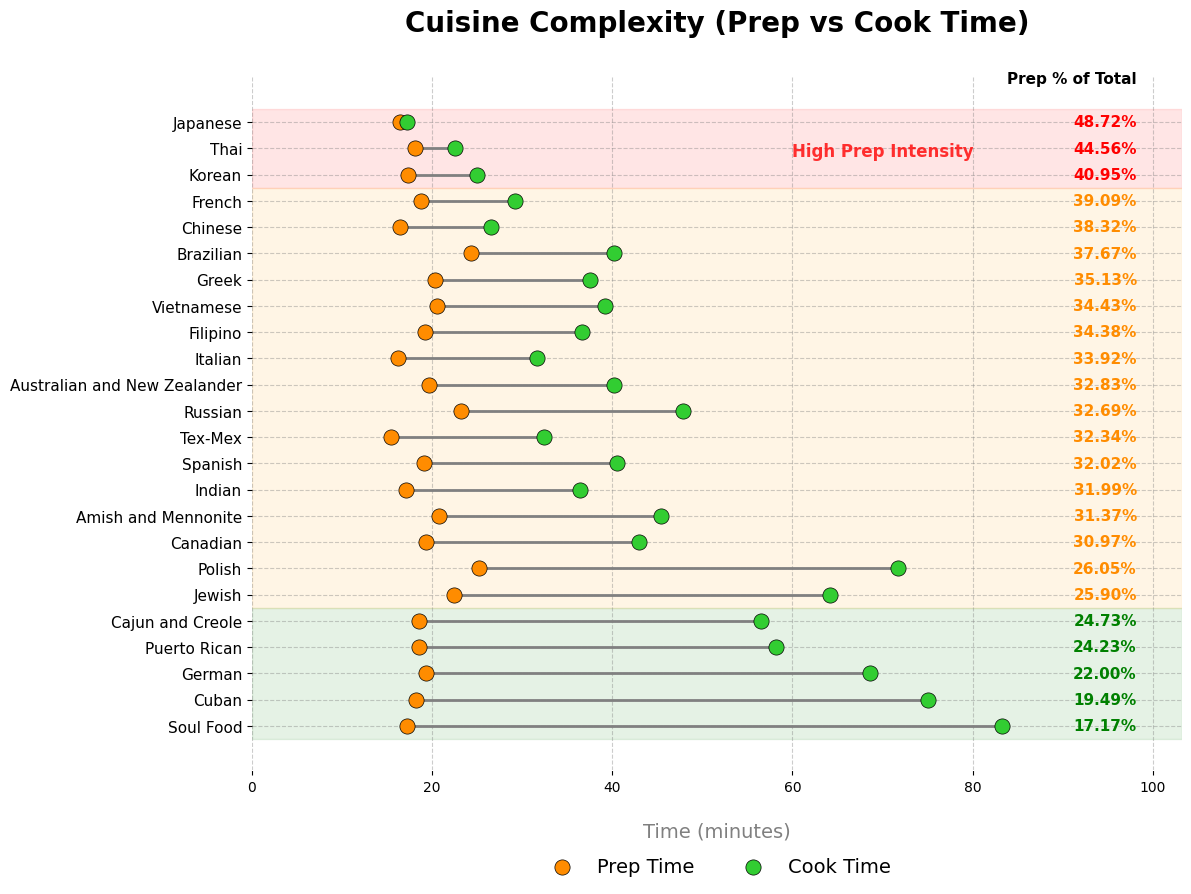

In [15]:
plt.style.use('default')
fig, ax = plt.subplots(figsize = (12, 9), facecolor = 'white')
ax.set_facecolor('white')

qn1 = qn1.sort_values(by = "prep_pct", ascending = False).reset_index(drop = True)
x_max = qn1["cook_time"].max()
column_x_pos = x_max + 15 
n = len(qn1)

for i, row in qn1.iterrows():
    if i < 3:
        text_color = "red"
    elif i >= n - 5:
        text_color = "green"
    else:
        text_color = "darkorange"
    ax.plot([row["prep_time"], row["cook_time"]], [i, i], color = "grey", linewidth = 2, zorder = 1)
    ax.text(column_x_pos, i, f"{row['prep_pct']:.2f}%", va = "center", ha = "right", color = text_color, fontweight = 'bold', fontsize = 11)
    
ax.scatter(qn1["prep_time"], qn1.index, color = "darkorange", s = 120, label = "Prep Time", zorder = 3, edgecolors = 'black', linewidth = 0.5)
ax.scatter(qn1["cook_time"], qn1.index, color = "limegreen", s = 120, label = "Cook Time", zorder = 3, edgecolors = 'black', linewidth = 0.5)

ax.set_yticks(qn1.index)
ax.set_yticklabels(qn1["country"], fontsize = 11, color = "black")

plt.title("Cuisine Complexity (Prep vs Cook Time)\n", fontsize = 20, fontweight = "bold", loc = "center", pad = 10, color = "black")

ax.text(column_x_pos, -1.5, "Prep % of Total", fontsize = 11, fontweight = "bold", ha = "right", color = "black")

ax.set_xlabel("\nTime (minutes)", color = 'gray', fontsize = 14)
ax.grid(True, axis = "both", linestyle = "--", alpha = 0.4, color = 'gray', zorder = 1)
ax.axhspan(-0.5, 2.5, color = "red", alpha = 0.10, zorder = 0)
ax.axhspan(2.5, n - 5.5, color = "orange", alpha = 0.10, zorder = 0)
ax.axhspan(n - 5.5, n - 0.5, color = "green", alpha = 0.10, zorder = 0) 
ax.text(60, 1.3, "High Prep Intensity", color="red", alpha = 0.8, fontsize = 12, fontweight = "bold")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color("white")

plt.legend(frameon = False, loc = "upper center", bbox_to_anchor = (0.5, -0.1), ncol = 2, fontsize = 14)

plt.xlim(0, column_x_pos + 5)
plt.gca().invert_yaxis() 

plt.show()

#### **Why Choose a Dumbbell Chart?**

The dumbbell chart is particularly well-suited for this analysis because it simultaneously encodes the two variables per cuisine, prep time and cook time, while making the relationship between them the visual centrepiece, rather than just the values themselves. It is highly effective in visualsing the gap between and range of two variables.

A bar chart, for instance, would show each cuisine's total time well, but would obscure whether that time is spent actively or passively. 

A scatter plot could plot both variables but would lose the direct visual connection between the two dots for the same cuisine. 

The dumbbell chart solves both problems at once: each dot represents one type of time commitment, and the line between them directly shows the gap, which is precisely what the question of complexity is about.

#### **Observations**

We first observe that for all cuisines, the cook time is longer than the prep time.

- The length of the line connecting each pair of dots represents the gap between
prep and cook time — a short line means the cook stays continuously engaged from 
start to finish, while a long line means a brief window of active work followed by 
an extended period of passive cooking.

- At the top, Asian cuisines — Japanese, Thai, and Korean — cluster tightly, their 
orange and green dots sitting just minutes apart. These cuisines ask the most of the 
chef proportionally. Japanese cuisine on average spends nearly half its total time (48.7%) 
in active preparation.

- The short line reflects near-continuous engagement that requires technique and precision.

- The average prep time percentage is ~32%. Moving down the graph, the lines progressively 
stretch. Cuisines such as Polish, Jewish, and German see cook times much greater than their 
prep times, seen by the much greater separation between the orange and green dots. For such
dishes, the chef commits a small window of active work, then largely steps away. The dish is
still complex in its own right, but the cook time allows the chef to prepare other things 
in between.

- Soul Food lies at the extreme, with only 17.2% of its total time spent on prep and an 
~65-minute disparity between dots. It is the most time-intensive cuisine in this dataset — not
the most demanding on skill, but the most demanding on patience. Its dishes on average take a long time to complete.

#### **Insight**

In professional kitchens, Mise en Place (everything in its place) is the gold standard. Cuisines at the top of our chart (Japanese and Thai) require 100% Mise en Place. You cannot start cooking a stir-fry and then decide to chop an onion; the "complexity" comes from the fact that the prep and cook times are nearly identical, meaning the transition between both must be seamless.

Cuisines at the bottom (Soul Food and Cajun) have a high buffer time. This means the chef has "down-time" to clean the kitchen, prepare a side dish, or rest. This is a vital distinction for a user deciding what to cook, depeneding on time constraints.

#### **Conclusion**
The broader conclusion is that total time does not entirely capture how demanding a cuisine is to cook. A dish that takes 90 minutes but only needs 15 minutes of prep feels very different from one that takes 35 minutes of focused, hands-on work the whole way through.

In practice, one lets the chef step back while the other doesn't. This distinction is well recognised in culinary education — Siegel (2019) notes that cooks often regard the most difficult dishes as those that appear deceptively simple, precisely because there is nowhere to hide: no elaborate sauces or complex processing techniques to compensate for a lapse in technique or attention. What our chart does is make that same idea visible at the cuisine level. It shifts the idea of "complexity" away from how long a recipe takes, and toward how much sustained attention it actually asks of the chef.

Our chart helps to explain why Asian cuisines often feel more complex despite shorter total times. Many dishes rely on precise timing, knife skills, and heat control rather than long passive cooking. As Fuchsia Dunlop (2019) observes in her work on Chinese cooking, the challenge lies in the intensity and coordination of techniques—ingredients must be prepared in advance and executed rapidly, leaving little margin for error. In this sense, complexity arises not from duration, but from the concentration of skill and attention required throughout the cooking process.

### **Q2. Does complexity predict nutrition?**

Before we can start analysising this question, we need to define nutrition score per recipe. 

#### **Defining a Nutrition Score**
##### **(a) Min-max normalise protein, fat, carbs**
Each recipe has different nutrient values, so the variables are on different scales. We first rescale protein, fat, and carbs to a 0–1 range so they can be compared fairly.

In [16]:
cuisines_norm = cuisines_final.copy()
nutrients = ["protein", "fat", "carbs"]

for nutrient in nutrients:
    lower = cuisines_final[nutrient].quantile(0.01)
    upper = cuisines_final[nutrient].quantile(0.99)
    cuisines_norm[nutrient + "_norm"] = (cuisines_norm[nutrient] - lower) / (upper - lower)

##### **(b) Combine into one nutrition score**
We define the nutrition score as:
- higher protein = better
- higher fat = worse
- higher carbs = worse

In [17]:
cuisines_norm["nutrition_score"] = (
      cuisines_norm["protein_norm"]
    - cuisines_norm["fat_norm"]
    - cuisines_norm["carbs_norm"]
)

cuisines_norm[["name", "protein_norm", "fat_norm", "carbs_norm", "nutrition_score"]].head()

,name,protein_norm,fat_norm,carbs_norm,nutrition_score
0,Saganaki (Flaming Greek Cheese),0.226757,0.304878,0.118303,-0.196424
1,Coney Island Knishes,0.099206,0.207317,0.253507,-0.361618
2,Diana's Hawaiian Bread Rolls,0.014172,0.036585,0.067602,-0.090015
4,Tex-Mex Sheet Cake,0.099206,0.280488,0.481663,-0.662944
5,Newfoundland Jigg's Dinner,0.651927,0.292683,1.208383,-0.849138


##### **(c) Normalise nutrition score**

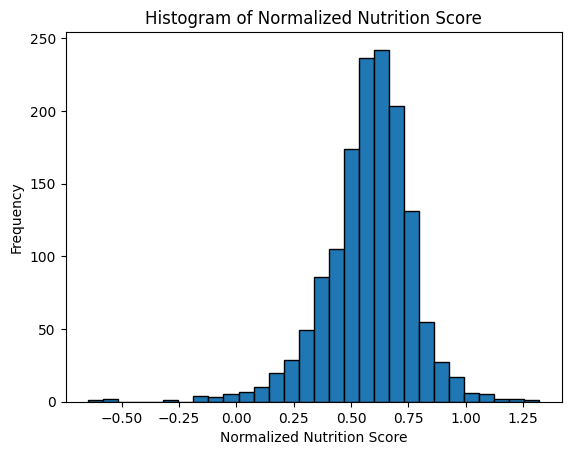

In [18]:
# Normalise nutrition_score to 0-1
score_min = cuisines_norm["nutrition_score"].quantile(0.01)
score_max = cuisines_norm["nutrition_score"].quantile(0.99)

if score_max == score_min:
    cuisines_norm["nutrition_score_norm"] = 0.0
else:
    cuisines_norm["nutrition_score_norm"] = (
        cuisines_norm["nutrition_score"] - score_min
    ) / (score_max - score_min)

#check distribution for nutrition score (not part of the 3 plots)
plt.hist(cuisines_norm["nutrition_score_norm"], bins=30, edgecolor="black")
plt.xlabel("Normalized Nutrition Score")
plt.ylabel("Frequency")
plt.title("Histogram of Normalized Nutrition Score")
plt.show()

To better assess whether complexity predicts nutritional outcomes, we narrow our analysis to the top 5 most complex and top 5 least complex cuisines.

In [19]:
# Complexity order
top_5 = [
    "Japanese",
    "Thai",
    "Korean",
    "French",
    "Chinese",
]

bottom_5 = [
    "Soul Food",
    "Cuban",
    "German",
    "Puerto Rican",
    "Cajun and Creole"
]

complexity_rank_map_1 = {cuisine: rank + 1 for rank, cuisine in enumerate(top_5)}
complexity_rank_map_2 = {cuisine: rank + 1 for rank, cuisine in enumerate(bottom_5)}

# Keep only selected cuisines
plot_df_top5 = cuisines_norm[cuisines_norm["country"].isin(top_5)].copy()
plot_df_bottom5 = cuisines_norm[cuisines_norm["country"].isin(bottom_5)].copy()

# Assign complexity rank
plot_df_top5["complexity_rank"] = plot_df_top5["country"].map(complexity_rank_map_1)
plot_df_bottom5["complexity_rank"] = plot_df_bottom5["country"].map(complexity_rank_map_2)

In [20]:
#Top 5 - nutrition score 
nutri_1 = (
    plot_df_top5.groupby("country")
    .agg(
        nutrition_score=("nutrition_score_norm", "mean"),
    )
)

nutri_1 = nutri_1.loc[top_5]
nutri_1.columns = ["Nutrition"]

#Bottom 5 - nutri score
nutri_2 = (
    plot_df_bottom5.groupby("country")
    .agg(
        nutrition_score=("nutrition_score_norm", "mean"),
    )
)

nutri_2 = nutri_2.loc[bottom_5]
nutri_2.columns = ["Nutrition"]

##############################################

#top 5 - protein
protein_plot_1 = (
    plot_df_top5.groupby("country")
    .agg(
        protein=("protein_norm", "mean")
    )
)

protein_plot_1 = protein_plot_1.loc[top_5]
protein_plot_1.columns = ["Protein"]

#bottom 5 - protein
protein_plot_2 = (
    plot_df_bottom5.groupby("country")
    .agg(
        protein=("protein_norm", "mean")
    )
)

protein_plot_2 = protein_plot_2.loc[bottom_5]
protein_plot_2.columns = ["Protein"]

##############################################

#top 5 - fats 
fat_plot_1 = (
    plot_df_top5.groupby("country")
    .agg(
        fat=("fat_norm", "mean")
    )
)

fat_plot_1 = fat_plot_1.loc[top_5]
fat_plot_1.columns = ["Fats"]

#bottom 5 - fats
fat_plot_2 = (
    plot_df_bottom5.groupby("country")
    .agg(
        fat=("fat_norm", "mean")
    )
)

fat_plot_2 = fat_plot_2.loc[bottom_5]
fat_plot_2.columns = ["Fats"]

##############################################

#top 5 - carbs
carbs_plot_1 = (
    plot_df_top5.groupby("country")
    .agg(
        carbs=("carbs_norm", "mean")
    )
)

carbs_plot_1 = carbs_plot_1.loc[top_5]
carbs_plot_1.columns = ["Carbs"]

#bottom 5 - carbs
carbs_plot_2 = (
    plot_df_bottom5.groupby("country")
    .agg(
        carbs=("carbs_norm", "mean")
    )
)

carbs_plot_2 = carbs_plot_2.loc[bottom_5]
carbs_plot_2.columns = ["Carbs"]


We construct heatmaps to compare the nutritional profiles of the top 5 most complex and top 5 least complex cuisines.

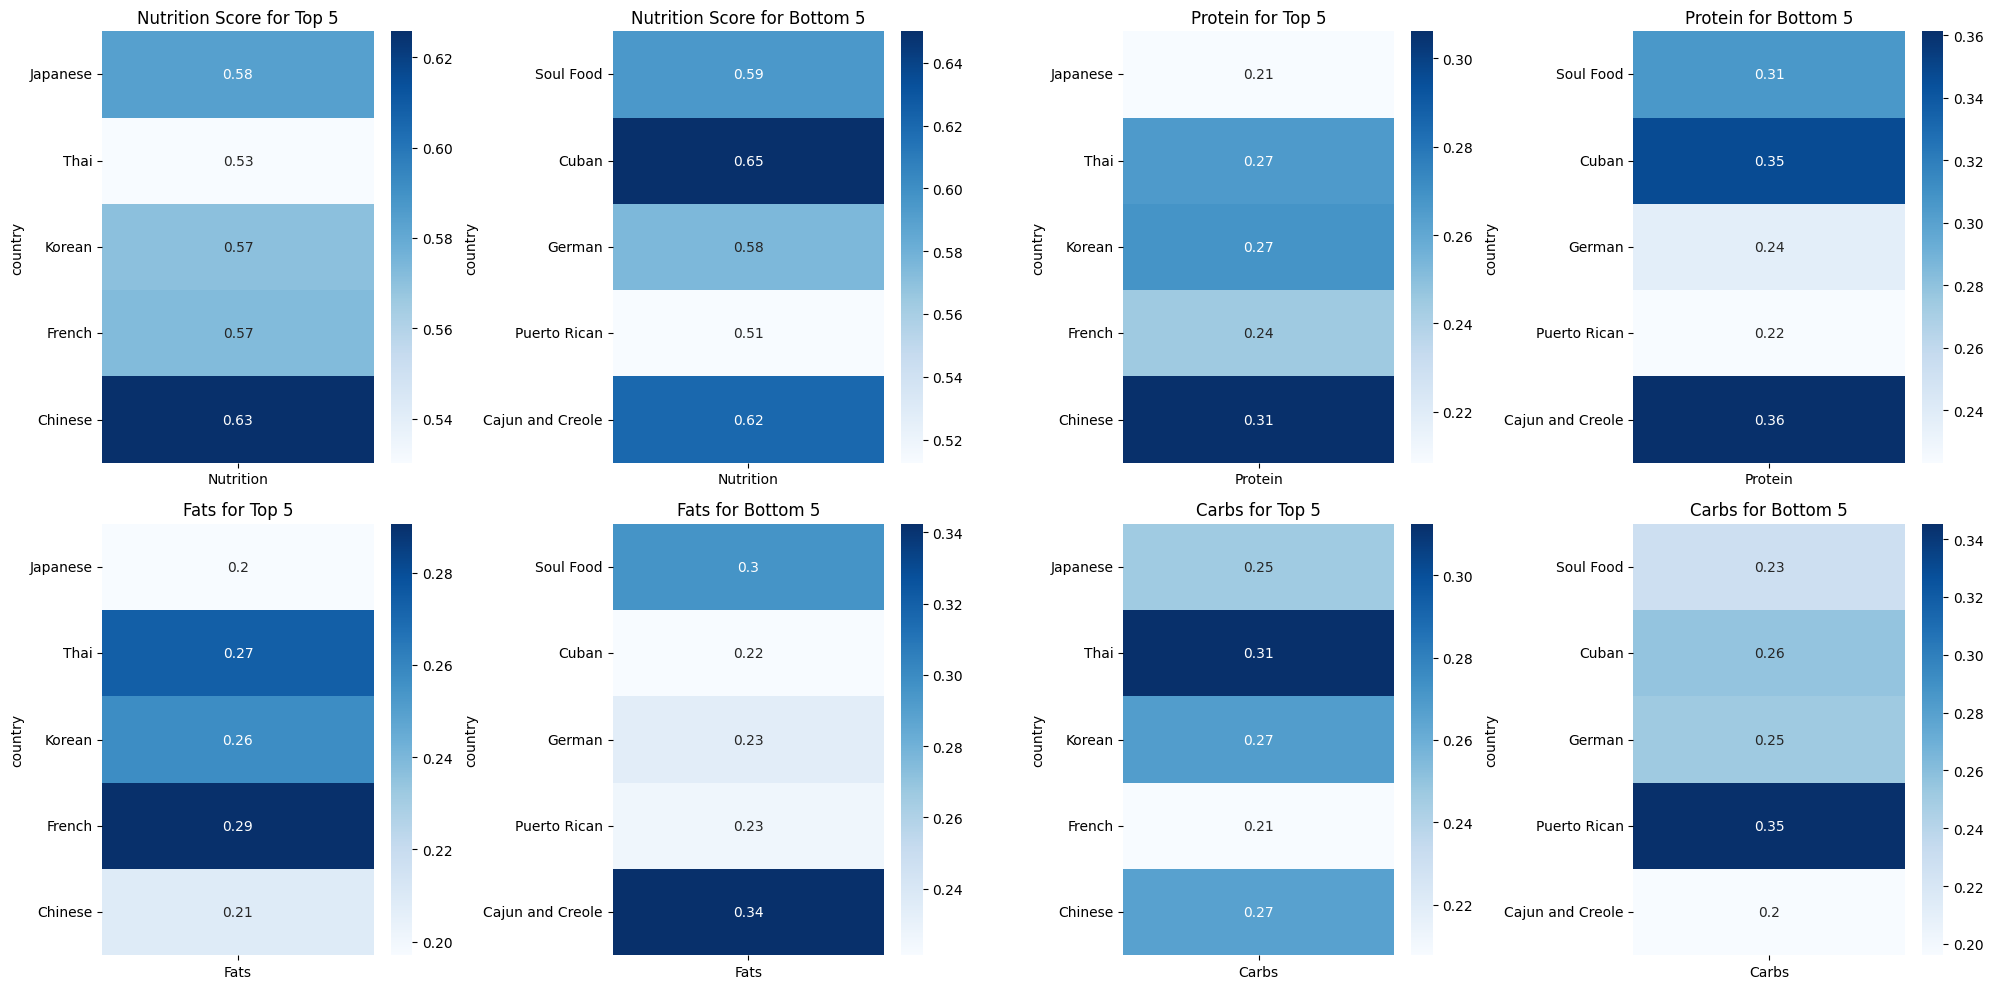

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

sns.heatmap(nutri_1, ax=axes[0, 0], cmap="Blues", annot=True)
axes[0, 0].set_title("Nutrition Score for Top 5")
sns.heatmap(nutri_2, ax=axes[0, 1], cmap="Blues", annot=True)
axes[0, 1].set_title("Nutrition Score for Bottom 5")

sns.heatmap(protein_plot_1, ax=axes[0, 2], cmap="Blues", annot=True)
axes[0, 2].set_title("Protein for Top 5")
sns.heatmap(protein_plot_2, ax=axes[0, 3], cmap="Blues", annot=True)
axes[0, 3].set_title("Protein for Bottom 5")

sns.heatmap(fat_plot_1, ax=axes[1, 0], cmap="Blues", annot=True)
axes[1, 0].set_title("Fats for Top 5")
sns.heatmap(fat_plot_2, ax=axes[1, 1], cmap="Blues", annot=True)
axes[1, 1].set_title("Fats for Bottom 5")

sns.heatmap(carbs_plot_1, ax=axes[1, 2], cmap="Blues", annot=True)
axes[1, 2].set_title("Carbs for Top 5")
sns.heatmap(carbs_plot_2, ax=axes[1, 3], cmap="Blues", annot=True)
axes[1, 3].set_title("Carbs for Bottom 5")

for ax in axes.flat:
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, va='center')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha='center')

plt.tight_layout()
plt.show()

#### **Why choose a Heat Map?**

- This set of heatmaps visualises four variables across cuisines: overall nutrition score, protein, fats, and carbohydrates. The y-axis represents countries (categorical) which represents the different cuisines, while colour intensity encodes the average value of each metric (continuous). We look at nutrition score, protein, fats and carbs to find out whether the cuisine is nutritious. 

- A heatmap is well-suited here as it enables quick, side-by-side comparison across cuisines and nutritional dimensions, allowing patterns in both overall nutrition and macronutrient composition to be identified at a glance. This makes it effective for assessing whether culinary complexity (proxied by cuisine differences) relates to nutritional outcomes in a compact format.

- Colour intensity further enhances interpretation, with darker blue indicating higher values and lighter shades lower values—where darker shades are more desirable for nutrition score and protein, and lighter shades may be preferable for fats and carbohydrates depending on balance.


#### **Nutritional Trends**

`Nutrition Score`
- Cuisines such as Cuban (0.65), Chinese (0.63), and Cajun & Creole (0.62) record the highest nutrition scores, while Puerto Rican (0.51) and Thai (0.53) are lower.
- The range remains relatively narrow (~0.51 to 0.65), suggesting that even across the most and least complex cuisines, nutritional differences are modest.
- Notably, both more complex (e.g., Chinese) and less complex cuisines (e.g., Cuban) has the most intense blue, indicating no clear pattern linking complexity to higher nutrition.

`Protein`
- Cajun & Creole (0.36) and Cuban (0.35) cuisines have the highest protein proportions, while Japanese (0.21) and Puerto Rican (0.22) are lower.
- Some cuisines may emphasise protein-rich ingredients (e.g., meats, legumes, or seafood) more heavily. 
- However, higher protein content does not always align with higher overall nutrition scores, indicating that protein alone does not determine nutritional quality, and further considerations are needed for a balanced macronutrient profile.

`Fats`
- Cajun & Creole (0.34) and Soul Food (0.30) show the highest fat proportions, while Japanese (0.20) and Chinese (0.21) are lower.
- Interestingly, cuisines with higher fat proportions do not necessarily have lower nutrition scores. 
- This suggests that fat content is not inherently negative, and may reflect the use of healthier fats (e.g., olive oil in Mediterranean cuisines). Highlighting that nutritional quality depends on the type and balance of nutrients rather than any single component.

`Carbohydrates`
- Puerto Rican (0.35) and Thai (0.31) cuisines are the most carbohydrate-heavy, while Cajun & Creole (0.20) and French (0.21) are lower.
- Despite this variation, high carbohydrate levels do not clearly correspond to lower nutrition scores. 
- This supports the idea that macronutrient balance, rather than dominance of a single nutrient, is key to overall nutrition.


#### **Conclusion**

- The heatmaps show that the more complex cuisines (e.g., Japanese, Thai, Korean) do not consistently achieve higher nutrition scores, and in some cases fall below less complex cuisines.
- This suggests that greater effort or skill does not necessarily translate into healthier or more nutritious outcomes, but may instead reflect culinary style and preparation methods.
- Less complex cuisines (e.g., German, Soul Food, Puerto Rican) though being less “actively complex," perform similarly, and at times even outperform more complex cuisines in nutrition (e.g., Cuban and Cajun & Creole ranking among the highest).
- Taken together, the comparison between the most and least complex cuisines strengthens the conclusion that there is no meaningful relationship between cooking complexity and nutritional quality.
- Even at the extremes of complexity, nutrition scores remain tightly clustered, and high-performing cuisines emerge from both groups. Suggesting that complexity and nutrition are fundamentally decoupled: complexity is driven by process and effort, while nutrition is determined by ingredient composition and macronutrient balance.

#### **Q3. Does nutrition predict popularity?**
We first aggregate to country level

In [22]:
# manually map regional/cultural cuisines to their closest country
cuisine_to_country = {
    "Amish and Mennonite"         : "United States",
    "Cajun and Creole"            : "United States",
    "Soul Food"                   : "United States",
    "Tex-Mex"                     : "United States",
    "Australian and New Zealander": "Australia",
    "Puerto Rican"                : "United States",
}

cuisines_norm["country"] = cuisines_norm["country"].replace(cuisine_to_country)

# aggregate to one row per country
country_stats = cuisines_norm.groupby("country").agg(

    mean_nutrition_score = ("nutrition_score_norm", "mean"),  # avg nutrition score per country
    mean_avg_rating      = ("avg_rating",       "mean"),  # avg rating per country
    recipe_count         = ("name",             "count")  # how many recipes per country

).reset_index()

Mapping of country names to ISO-3 codes

In [23]:
iso_mapping = {
    "Australia"    : "AUS",
    "Brazilian"    : "BRA",
    "Canadian"     : "CAN",
    "Chinese"      : "CHN",
    "Cuban"        : "CUB",
    "Filipino"     : "PHL",
    "French"       : "FRA",
    "German"       : "DEU",
    "Greek"        : "GRC",
    "Indian"       : "IND",
    "Italian"      : "ITA",
    "Japanese"     : "JPN",
    "Jewish"       : "ISR",  # mapped to Israel, since Israel is the country most associated with Jewish culinary
    "Korean"       : "KOR",
    "Polish"       : "POL",
    "Russian"      : "RUS",
    "Spanish"      : "ESP",
    "Thai"         : "THA",
    "United States": "USA",
    "Vietnamese"   : "VNM",
}

country_stats["iso_alpha"] = country_stats["country"].map(iso_mapping)


Building chorepleth map 

In [24]:
world = gpd.read_file(
    "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
)

world = world[world["SOVEREIGNT"] != "Antarctica"]

merged = world.merge(
    country_stats,
    how="left",
    left_on="ISO_A3",     
    right_on="iso_alpha" 
)

/var/folders/48/y8zm96nj6953gxgcxw01_87c0000gn/T/ipykernel_53420/4127686317.py:23: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  merged["lon"] = merged.geometry.centroid.x
/var/folders/48/y8zm96nj6953gxgcxw01_87c0000gn/T/ipykernel_53420/4127686317.py:24: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  merged["lat"]  = merged.geometry.centroid.y


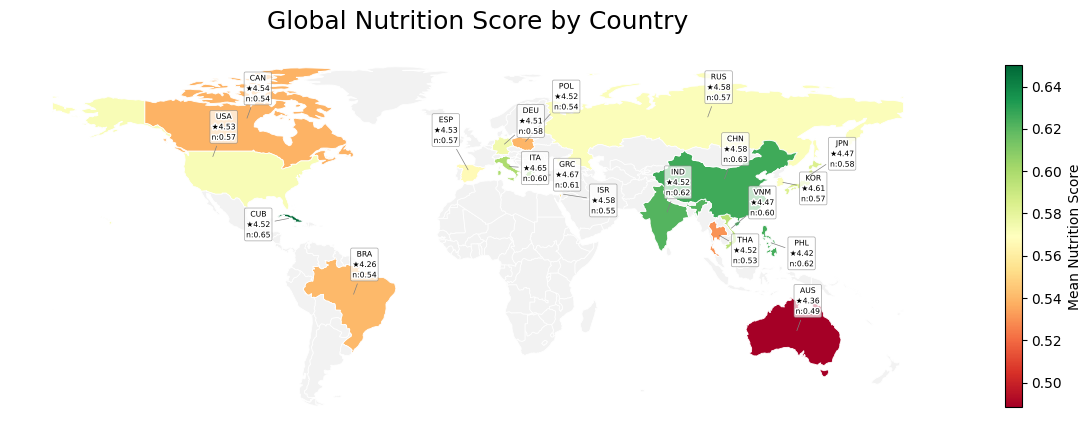

In [25]:
# Plotting the choropleth map
fig, ax = plt.subplots(figsize=(12, 6))

merged.plot(
    column="mean_nutrition_score",
    cmap="RdYlGn",
    linewidth=0.6,
    edgecolor="white",
    legend=True,
    ax=ax,
    missing_kwds={
        "color": "#f2f2f2",
        "edgecolor": "white",
        "label": "No data"
    },
    legend_kwds={
        "shrink": 0.6,
        "label": "Mean Nutrition Score"
    }
)

# Compute centroids for label placement
merged["lon"] = merged.geometry.centroid.x
merged["lat"]  = merged.geometry.centroid.y

# Custom offsets for crowded regions 
offsets = {
    "FRA": (10, 12),  "DEU": (12, 5),   "GRC": (15, -5),
    "ISR": (18, -8),  "POL": (18, 14),   "ESP": (-10, 12),
    "ITA": (12, -6),  "KOR": (14, -8),  "JPN": (16, 5),
    "PHL": (14, -10), "VNM": (14, 6),  "THA": (12, -12),
    "CUB": (-14, -8), "GBR": (-12, 10),
}

# Annotate each country that has data 
labeled = merged.dropna(subset=["mean_nutrition_score"])

for _, row in labeled.iterrows():
    iso  = row["iso_alpha"]
    lon, lat = row["lon"], row["lat"]
    dx, dy   = offsets.get(iso, (5, 8))
    label    = f"{iso}\n★{row['mean_avg_rating']:.2f}\nn:{row['mean_nutrition_score']:.2f}"

    ax.annotate(
        text       = label,
        xy         = (lon, lat),
        xytext     = (lon + dx, lat + dy),
        fontsize   = 5.5,
        ha         = "center",
        color      = "black",
        arrowprops = dict(arrowstyle="-", color="gray", lw=0.5),
        path_effects = [pe.withStroke(linewidth=2, foreground="white")],
        bbox       = dict(
            boxstyle  = "round,pad=0.2",
            facecolor = "white",
            edgecolor = "gray",
            alpha     = 0.7,
            linewidth = 0.5
        )
    )

ax.set_title("Global Nutrition Score by Country", fontsize=18, pad=15)
ax.axis("off")

plt.tight_layout()
plt.show()

#### **Why choose a Chloropleth Map?**

- A choropleth map is appropriate here because the unit of analysis is the country itself, making geography the most natural and intuitive organising dimension for comparing nutritional scores across nations. 
- The colour gradient allows readers to immediately identify regional clustering and outliers, such as the concentration of high scores in Asia versus the low scores of Australia and Brazil. 
- Since the research involves cross-country comparisons, mapping values directly onto their geographic locations allows spatial patterns and cultural or regional dietary trends to be surfaced at a glance.


##### **Overall Pattern**
- The map shows that mean nutrition scores vary within a relatively narrow range, from about 0.49 to 0.65.
- There is no single region that consistently dominates the highest scores; instead, countries with stronger scores are spread across different parts of the world.
- This suggests that nutrition is shaped more by food culture, dietary habits, and broader food environments than by geography alone (Afshin et al., 2019; Popkin, 2017).
- Because the overall range is fairly small, the colour differences on the map should be interpreted as relative rather than large absolute gaps.
- Taken together, the map does not suggest a strong visual link between nutrition score and recipe popularity.


##### **Regional Trends**

`Asia`
- Countries such as China (0.63, ★4.58) and India (0.62, ★4.52) have relatively higher nutrition scores, which may reflect diets that traditionally include more vegetables, grains, and legumes.
- Vietnam (0.60, ★4.47) and Thailand (0.53, ★4.52) are slightly lower, but the difference in ratings remains small.
- Overall, the variation in nutrition scores across Asian cuisines does not translate into a meaningful difference in popularity (Popkin, 2017).

`Europe`
- Most European countries fall within a similar mid-range of nutrition scores, around 0.54 to 0.61.
- Italy (0.60, ★4.65) and Greece (0.61, ★4.67) score slightly higher, while Germany (0.58, ★4.51) and Poland (0.54, ★4.52) are a bit lower.
- Even so, these score differences do not correspond to a clear pattern in ratings, suggesting that popularity is not strongly driven by nutrition alone.


##### **Outliers**
- Australia (0.49, ★4.36) stands out as a lower-scoring country and also has one of the lower average ratings.
- However, this pattern is not consistent across the rest of the dataset. For example, Cuba (0.65, ★4.52) has one of the highest nutrition scores, but its rating is only moderate.
- Brazil (0.54, ★4.26) also shows that a mid-range nutrition score does not guarantee stronger popularity.
- These exceptions suggest that any apparent relationship between nutrition and popularity is weak and not generalisable across countries.
- Structural differences in food systems and levels of processing may help explain the nutrition variation, but they do not appear to translate directly into higher ratings (Monteiro et al., 2019).


##### **Conclusion**
- Overall, the nutrition score shows a weak positive relationship with popularity.
- In other words, recipes with better diet quality are not necessarily rated more highly in this dataset.
- This suggests that popularity is influenced by other factors besides nutritional quality, such as taste preference, familiarity, and cooking style.


##### **Key note:**
- The nutrition scores fall within a relatively narrow range of about 0.49 to 0.65.
- Although the colour scale makes the differences look larger, the actual variation between countries is small.
- This is why the map should be interpreted as showing relative differences rather than large nutritional gaps.


## **Summary**

**1. Weak overall link between complexity and nutrition** 

Across all cuisines, there is no clear overarching trend that more complex dishes are more nutritious. Both high and low complexity cuisines appear across the range of nutrition scores, suggesting that complexity in preparation does not inherently translate into healthier outcomes.

**2. Nutrition and Popularity Do Not Strongly Align** 

The patterns suggest that more nutritious cuisines are not consistently more popular. Highly rated cuisines are distributed across different nutrition levels, implying that consumer preference is not primarily driven by nutritional quality.

**3. Complexity Does Not Drive Popularity** 

Similarly, more complex cuisines are not consistently rewarded with greater popularity. Highly rated cuisines are found across both low and high levels of complexity and nutrition. There are some simpler cuisines achieve higher ratings than more complex ones, suggesting that ease of preparation does not affect popularity. This suggests that factors such as taste, familiarity, and cultural exposure likely play a larger role in popularity than either nutrition or cooking effort.

**4. Overall Insight: Independent Relationships** 

Taken together, the findings suggest that **cooking complexity, nutritional value, and popularity** are largely independent.
- Complexity does not reliably predict better nutrition
- Nutrition does not guarantee higher popularity
- Popularity is influenced by broader, non-nutritional factors

**5. Final Takeaway** 

Overall, the analysis indicates that cooking complexity is not a meaningful signal of either nutritional value or popularity, and healthier options are not necessarily the most favored. This highlights the importance of considering other drivers such as taste, accessibility, and cultural familiarity when interpreting food preferences. Future research could look at ingredient-level analysis, portion sizes, or consumer preference data (eg. flavor profiles, price, accessibility) to better understand what truly drives both nutrition and popularity.

In summary, while complex cuisines may appear more sophisticated, they do not systematically offer better nutrition nor receive greater public reward, pointing to a disconnect between effort, health value, and consumer preference.

#### **Teamwork**
- All members conducted their own initial exploration of the dataset to familiarise themselves with it. The team then discussed and agreed on a common approach to data cleaning, which was carried out by Wan Yu.
- Lionel and Terence worked on the visualisation and analysis for Q1 (What makes a cuisine complex?). Wan Yu and Ying Rou worked on Q2 (Does complexity predict nutrition?). Jessie and Shao En worked on Q3 (Does nutrition predict popularity?).
- Wan Yu worked on summary. 


#### **Dataset source**

- Thomas Mock, & TidyTuesday Contributors. (2025). TidyTuesday: A weekly social data project — All Recipes (2025-09-16). Github. [`Source`](https://github.com/rfordatascience/tidytuesday/blob/main/data/2025/2025-09-16/readme.md)


#### **References**

- Afshin, A., Sur, P. J., Fay, K. A., Cornaby, L., Ferrara, G., Salama, J. S., … Murray, C. J. L. (2019). Health effects of dietary risks in 195 countries, 1990–2017. The Lancet, 393(10184), 1958–1972.

- Cena, H., & Calder, P. C. (2023). Defining a healthy diet: Evidence for the role of macronutrient balance in health and disease. Nutrients, 15(4), 1029. [`Source`](https://doi.org/10.3390/nu15041029)

- Dunlop, F. (2019). The food of Sichuan. W. W. Norton & Company.[`Source`](https://catalog.myrichlandlibrary.org/Record/240598?com)

- Louzada, M. L. (2022). Consumption of ultra-processed foods in Brazil: distribution and temporal evolution 2008–2018. [`Source`](https://www.scielo.br/j/rsp/a/4NgBXsYpKjrKHvCBJ876P8F/?format=pdf&lang=en)

- Monteiro, C. A., Cannon, G., Levy, R. B., Moubarac, J.-C., Louzada, M. L. C., Rauber, F., … Jaime, P. C. (2019). Ultra-processed foods: What they are and how to identify them. Public Health Nutrition, 22(5), 936–941.

- Popkin, B. M. (2017). Relationship between shifts in food system dynamics and acceleration of the global nutrition transition. Nutrition Reviews, 75(2), 73–82.

- Siegel, T. (2019, May 21). The complexity of simple cooking. Institute of Culinary Education. [`Source`](https://www.ice.edu/blog/simple-cooking)

- Traynor, I. (2024). The links between home cooking and health are not a given. Nature Food. [`Source`](https://www.nature.com/articles/d42473-024-00020-7.pdf) 

